# Course 12: AI for Accessibility
## Session 2: Speech recognition for Bangla

**Goal:** compute log-mel features with NumPy, train a small CTC speech recognizer on synthetic spoken digits with Bangla transcripts, and measure word and character error rates in clean and noisy conditions.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: frames, the mel scale and CTC
Do these on paper, then run the cell.

* **Frames.** Audio sampled at 8,000 samples per second is cut into windows of 25 ms that start every 10 ms (the hop). How many samples are in one window and in one hop, and how many complete windows fit in 1 second?
* **The mel scale.** $m = 2595 \log_{10}(1 + f/700)$ spaces frequencies roughly the way we hear pitch: equal steps in mel sound like equal steps in pitch, so high frequencies are squeezed together. What is $m$ for $f$ = 1,000 Hz?
* **CTC.** Connectionist temporal classification (CTC, Graves et al. 2006) lets a network output one symbol per frame, including a **blank** `-` that means "nothing new here". To read the output, first merge repeated symbols, then delete the blanks. What does the frame sequence `a a - a b b - b` become? How many 3-frame sequences over {a, b, -} give `ab`?

If every symbol has probability 1/3 at every frame, CTC gives `ab` the probability (number of such sequences)/27, and the CTC loss is minus its logarithm. The cell checks this with PyTorch's `nn.CTCLoss`.

In [1]:
import time
import itertools
import unicodedata
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.signal import get_window, stft

torch.set_num_threads(1)
t_start = time.time()
np.random.seed(0); torch.manual_seed(0)

SR = 8000
WIN, HOP = int(0.025 * SR), int(0.010 * SR)
print(f"window {WIN} samples, hop {HOP} samples, complete windows in 1 s: {1 + (SR - WIN) // HOP}")
mel = lambda f: 2595 * np.log10(1 + f / 700)
print(f"mel(1000 Hz) = {mel(1000):.1f}; mel(4000 Hz) = {mel(4000):.1f}")

def ctc_collapse(path, blank="-"):
    out, prev = [], None
    for s in path:
        if s != prev and s != blank:
            out.append(s)
        prev = s
    return "".join(out)

print("a a - a b b - b  ->", ctc_collapse("aa-abb-b"))
paths = ["".join(p) for p in itertools.product("ab-", repeat=3) if ctc_collapse("".join(p)) == "ab"]
print(f"3-frame sequences that give 'ab': {len(paths)} {paths}")
log_probs = torch.full((3, 1, 3), float(np.log(1 / 3)))           # (time, batch, symbols): blank = 0, a = 1, b = 2
loss = nn.CTCLoss(blank=0, reduction="sum")(log_probs, torch.tensor([[1, 2]]), torch.tensor([3]), torch.tensor([2]))
print(f"PyTorch CTC loss {loss.item():.4f}; -log({len(paths)}/27) = {-np.log(len(paths) / 27):.4f}")

window 200 samples, hop 80 samples, complete windows in 1 s: 98
mel(1000 Hz) = 1000.0; mel(4000 Hz) = 2146.1
a a - a b b - b  -> aabb
3-frame sequences that give 'ab': 5 ['aab', 'abb', 'ab-', 'a-b', '-ab']
PyTorch CTC loss 1.6864; -log(5/27) = 1.6864


### 2. From waveform to log-mel features, in NumPy
A recognizer does not read raw samples. It cuts the signal into short overlapping frames, multiplies each frame by a smooth window (Hann), and takes the fast Fourier transform (FFT) of each: this is the **short-time Fourier transform** (STFT). It then pools the energies with triangular **mel filters**, narrow at low frequencies and wide at high ones, and takes the logarithm, which compresses the huge range of loudness. Whisper, for example, uses 16 kHz audio, 400-sample (25 ms) windows, a 160-sample (10 ms) hop and 80 or 128 mel bands, depending on the model. We use 8 kHz and 40 bands to stay small.

The test signal is synthetic: a chirp rising from 200 Hz to 3,000 Hz in one second, steady tones at 500 Hz and 2,000 Hz, and a little noise. We check our STFT against SciPy's.

STFT: 98 frames x 129 frequency bins; largest difference from scipy.signal.stft: 7.1e-15
mel filters: the first spans 0-68 Hz, the last spans 3583-4000 Hz
log-mel features: 98 frames x 40 bands = 3920 numbers for 8000 samples


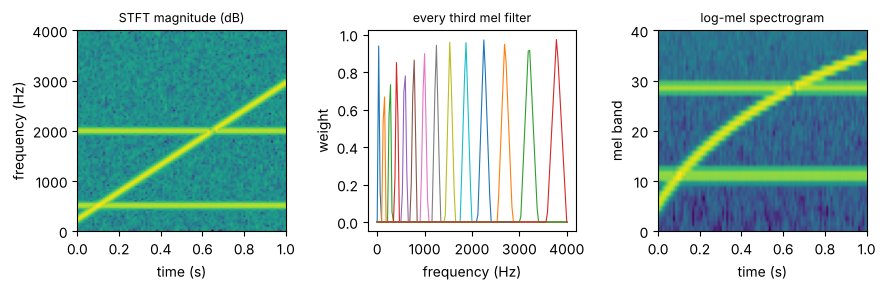

In [2]:
NFFT, NMEL = 256, 40
window = get_window("hann", WIN)                                   # the periodic Hann window that SciPy also uses

def stft_mag(x):
    n = 1 + (len(x) - WIN) // HOP
    idx = np.arange(WIN)[None, :] + HOP * np.arange(n)[:, None]    # (frames, WIN) sample indices
    return np.abs(np.fft.rfft(x[idx] * window, n=NFFT, axis=1))   # (frames, NFFT/2 + 1) magnitudes

def mel_filterbank(n_mels=NMEL, n_fft=NFFT, sr=SR):
    edges = 700 * (10 ** (np.linspace(0, mel(sr / 2), n_mels + 2) / 2595) - 1)   # equally spaced in mel, back to Hz
    freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)
    fb = np.zeros((n_mels, len(freqs)))
    for m in range(n_mels):
        lo, mid, hi = edges[m], edges[m + 1], edges[m + 2]
        fb[m] = np.clip(np.minimum((freqs - lo) / (mid - lo), (hi - freqs) / (hi - mid)), 0, None)
    return fb, edges

FB, EDGES = mel_filterbank()

def log_mel(x):
    return np.log(stft_mag(x) ** 2 @ FB.T + 1e-6)                   # (frames, NMEL)

t = np.arange(SR) / SR
sig = (np.sin(2 * np.pi * (200 * t + 1400 * t ** 2))                 # chirp: instantaneous frequency 200 + 2800 t Hz
       + 0.5 * np.sin(2 * np.pi * 500 * t) + 0.5 * np.sin(2 * np.pi * 2000 * t)
       + 0.05 * np.random.default_rng(0).normal(size=SR))
S = stft_mag(sig)
_, _, Z = stft(sig, fs=SR, window="hann", nperseg=WIN, noverlap=WIN - HOP, nfft=NFFT, boundary=None, padded=False)
print(f"STFT: {S.shape[0]} frames x {S.shape[1]} frequency bins; largest difference from scipy.signal.stft: "
      f"{np.abs(S - np.abs(Z.T) * window.sum()).max():.1e}")
print(f"mel filters: the first spans {EDGES[0]:.0f}-{EDGES[2]:.0f} Hz, the last spans {EDGES[-3]:.0f}-{EDGES[-1]:.0f} Hz")
LM = log_mel(sig)
print(f"log-mel features: {LM.shape[0]} frames x {LM.shape[1]} bands = {LM.size} numbers for {SR} samples")

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(20 * np.log10(S.T + 1e-6), origin="lower", aspect="auto", extent=[0, 1, 0, SR / 2])
ax[0].set_title("STFT magnitude (dB)", fontsize=9); ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("frequency (Hz)")
ax[1].plot(np.linspace(0, SR / 2, NFFT // 2 + 1), FB[::3].T, lw=0.8)
ax[1].set_title("every third mel filter", fontsize=9); ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("weight")
ax[2].imshow(LM.T, origin="lower", aspect="auto", extent=[0, 1, 0, NMEL])
ax[2].set_title("log-mel spectrogram", fontsize=9); ax[2].set_xlabel("time (s)"); ax[2].set_ylabel("mel band")
plt.tight_layout(); plt.show()

### 3. A synthetic "spoken digits" corpus
Real Bangla speech needs a download (section 8). Here each digit 0–9 is a made-up two-part sound, a little like a syllable with two vowels. Each part is a pair of tones, like the first two **formants** (the resonances of the mouth that make vowels sound different), plus a quiet low tone at the speaker's pitch. Each synthetic speaker shifts all frequencies by a factor between 0.85 and 1.15 and speaks at a random speed. An utterance is 3 to 6 digits, like part of a phone number, with white noise at a signal-to-noise ratio (SNR) between 10 and 30 dB; 0 dB means the noise is as loud as the speech. The transcripts are the Bangla number words. Some digits share their first part, so the model must listen to the whole sound.

In [3]:
rng = np.random.default_rng(0)
WORDS = ["শূন্য", "এক", "দুই", "তিন", "চার", "পাঁচ", "ছয়", "সাত", "আট", "নয়"]
VOWELS = [(f1, f2) for f1 in (300, 450, 600, 750) for f2 in (1000, 1400, 1800, 2200)]
TABLE, used = [], set()
while len(TABLE) < 10:                                              # 10 distinct two-part patterns
    i, j = rng.integers(0, len(VOWELS), 2)
    if i != j and (i, j) not in used:
        used.add((i, j)); TABLE.append((VOWELS[i], VOWELS[j]))
for d, (a, b) in enumerate(TABLE):
    print(f"digit {d} ({WORDS[d]}): tones {a} Hz then {b} Hz")

def to_text(digits):
    return " ".join(WORDS[d] for d in digits)

def speak(digits, rng):
    s, f0 = rng.uniform(0.85, 1.15), rng.uniform(100, 220)          # speaker: formant shift and pitch
    parts = [np.zeros(int(rng.uniform(0.05, 0.15) * SR))]
    for d in digits:
        for f1, f2 in TABLE[d]:
            n = int(rng.uniform(0.05, 0.11) * SR); tt = np.arange(n) / SR
            y = (np.sin(2 * np.pi * f1 * s * tt + rng.uniform(0, 6.3)) + 0.6 * np.sin(2 * np.pi * f2 * s * tt + rng.uniform(0, 6.3))
                 + 0.3 * np.sin(2 * np.pi * f0 * tt))
            parts.append(y * np.minimum(1, np.minimum(tt, tt[::-1]) / 0.01))   # 10 ms fade in and out
        parts.append(np.zeros(int(rng.uniform(0.0, 0.06) * SR)))
    parts.append(np.zeros(int(rng.uniform(0.05, 0.15) * SR)))
    return np.concatenate(parts)

def add_noise(x, snr_db, rng, kind="white"):
    if kind == "white":
        noise = rng.normal(size=len(x))
    else:                                                           # babble: three other speakers talking at once
        noise = sum(np.resize(speak(rng.integers(0, 10, 8), rng), len(x)) for _ in range(3))
    return x + noise * np.sqrt(np.mean(x ** 2) / (np.mean(noise ** 2) * 10 ** (snr_db / 10)))

def make_set(n, rng, snr=None, babble_snr=None):
    X, Y = [], []
    for _ in range(n):
        digits = rng.integers(0, 10, rng.integers(3, 7))
        x = speak(digits, rng)
        y = add_noise(x, rng.uniform(10, 30) if snr is None else snr, rng)
        if babble_snr is not None:                                  # babble measured against the clean speech
            y = y + (add_noise(x, babble_snr, rng, "babble") - x)
        X.append(log_mel(y).astype(np.float32)); Y.append(digits)
    return X, Y

Xtr, Ytr = make_set(1500, rng)
Xva, Yva = make_set(300, rng)
lens = [len(x) for x in Xtr]
print(f"{len(Xtr)} training and {len(Xva)} validation utterances; {min(lens)} to {max(lens)} frames (mean {np.mean(lens):.0f})")
print("example transcript:", to_text(Ytr[0]), " digits", [int(d) for d in Ytr[0]])

digit 0 (শূন্য): tones (750, 1400) Hz then (600, 1800) Hz
digit 1 (এক): tones (600, 1000) Hz then (450, 1000) Hz
digit 2 (দুই): tones (450, 1000) Hz then (300, 1000) Hz
digit 3 (তিন): tones (300, 1400) Hz then (300, 1000) Hz
digit 4 (চার): tones (300, 1800) Hz then (750, 1400) Hz
digit 5 (পাঁচ): tones (600, 1800) Hz then (750, 1800) Hz
digit 6 (ছয়): tones (600, 1000) Hz then (600, 1400) Hz
digit 7 (সাত): tones (750, 2200) Hz then (600, 2200) Hz
digit 8 (আট): tones (600, 1800) Hz then (600, 1000) Hz
digit 9 (নয়): tones (600, 1000) Hz then (750, 1800) Hz


1500 training and 300 validation utterances; 58 to 157 frames (mean 103)
example transcript: আট ছয় শূন্য তিন  digits [8, 6, 0, 3]


### 4. Scoring: edit distance, WER and CER
The **word error rate** (WER) is the smallest number of word substitutions, deletions and insertions that turn the reference into the recognizer's output, divided by the number of reference words. The **character error rate** (CER) does the same with characters (here Unicode code points, spaces included). Both are computed over a whole test set, not averaged per sentence, and both can exceed 1 when the output has many extra words. We write the edit distance (Levenshtein distance) with dynamic programming.

In [4]:
def edit_distance(ref, hyp):
    # smallest number of substitutions, deletions and insertions turning sequence ref into sequence hyp
    d = list(range(len(hyp) + 1))
    for i in range(1, len(ref) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(hyp) + 1):
            cur = min(d[j] + 1, d[j - 1] + 1, prev + (ref[i - 1] != hyp[j - 1]))
            prev, d[j] = d[j], cur
    return d[len(hyp)]

def wer(refs, hyps):
    return sum(edit_distance(r.split(), h.split()) for r, h in zip(refs, hyps)) / sum(len(r.split()) for r in refs)

def cer(refs, hyps):
    return sum(edit_distance(r, h) for r, h in zip(refs, hyps)) / sum(len(r) for r in refs)

ref, hyp = "আমি বাজারে যাব", "আমি বাজার যাব"                          # "I will go to the market": one vowel sign missing
print(f"reference has {len(ref.split())} words and {len(ref)} code points; WER {wer([ref], [hyp]):.3f}, CER {cer([ref], [hyp]):.3f}")
print(f"insertions: WER of 'এক এক দুই তিন' against 'এক দুই' = {wer(['এক দুই'], ['এক এক দুই তিন']):.2f}")

reference has 3 words and 14 code points; WER 0.333, CER 0.071
insertions: WER of 'এক এক দুই তিন' against 'এক দুই' = 1.00


### 5. A small bidirectional GRU trained with CTC
The model: a 1-D convolution over time with stride 2, which halves the number of frames; a bidirectional GRU, a recurrent layer that reads the frames forwards and backwards; and a linear layer that gives, for every output frame, log-probabilities over 11 symbols (the blank and the 10 digits). `nn.CTCLoss` adds up the probabilities of all frame sequences that collapse to the transcript, with a dynamic program in log space, and returns the negative log-likelihood. **Greedy decoding** takes the most likely symbol at each frame and collapses. Features are standardized with the training set's mean and standard deviation.

In [5]:
MU, SD = np.concatenate(Xtr).mean(axis=0), np.concatenate(Xtr).std(axis=0)

def batch(X, Y, idx):
    xs = [torch.tensor((X[i] - MU) / SD) for i in idx]
    return (nn.utils.rnn.pad_sequence(xs, batch_first=True), torch.tensor([len(x) for x in xs]),
            torch.tensor(np.concatenate([Y[i] for i in idx]) + 1), torch.tensor([len(Y[i]) for i in idx]))

class CTCRecognizer(nn.Module):
    def __init__(self, n_in=NMEL, h=64, n_out=11):
        super().__init__()
        self.conv = nn.Conv1d(n_in, h, kernel_size=5, stride=2, padding=2)
        self.gru = nn.GRU(h, h, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * h, n_out)

    def forward(self, x, lengths):
        z = torch.relu(self.conv(x.transpose(1, 2))).transpose(1, 2)
        z, _ = self.gru(z)
        return self.out(z).log_softmax(-1), (lengths - 1) // 2 + 1    # output frames after the stride-2 convolution

def greedy_decode(log_probs, lengths):
    best = log_probs.argmax(-1).numpy()
    return [[k - 1 for i, k in enumerate(b[:n]) if k != 0 and (i == 0 or k != b[i - 1])] for b, n in zip(best, lengths.numpy())]

def recognize(model, X):
    model.eval(); hyps = []
    with torch.no_grad():
        for s in range(0, len(X), 100):
            x, lengths, _, _ = batch(X, [np.zeros(1, int)] * len(X), range(s, min(s + 100, len(X))))
            hyps += greedy_decode(*model(x, lengths))
    model.train()
    return hyps

def score(model, X, Y):
    hyps = [to_text(h) for h in recognize(model, X)]
    refs = [to_text(y) for y in Y]
    return wer(refs, hyps), cer(refs, hyps)

torch.manual_seed(0)
model = CTCRecognizer()
print(f"model parameters: {sum(p.numel() for p in model.parameters()):,}")
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
ctc = nn.CTCLoss(blank=0, zero_infinity=True)
train_rng = np.random.default_rng(1)
for epoch in range(6):
    order, total = train_rng.permutation(len(Xtr)), 0.0
    for s in range(0, len(order), 32):
        x, lengths, targets, target_lengths = batch(Xtr, Ytr, order[s:s + 32])
        lp, out_lengths = model(x, lengths)
        loss = ctc(lp.transpose(0, 1), targets, out_lengths, target_lengths)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        total += loss.item() * len(lengths)
    w, c = score(model, Xva, Yva)
    print(f"epoch {epoch + 1}: training CTC loss {total / len(Xtr):.3f}; validation WER {w:.3f}, CER {c:.3f} "
          f"({time.time() - t_start:.0f} s)")

model parameters: 64,203


epoch 1: training CTC loss 3.813; validation WER 1.000, CER 1.000 (7 s)


epoch 2: training CTC loss 0.771; validation WER 0.047, CER 0.053 (10 s)


epoch 3: training CTC loss 0.086; validation WER 0.003, CER 0.003 (12 s)


epoch 4: training CTC loss 0.026; validation WER 0.002, CER 0.002 (15 s)


epoch 5: training CTC loss 0.012; validation WER 0.002, CER 0.002 (17 s)


epoch 6: training CTC loss 0.010; validation WER 0.000, CER 0.000 (20 s)


### 6. Inside the recognizer, and one scoring trap
CTC models tend to put most of the probability on the blank and fire a short burst, often called a **spike**, for each symbol. The plot shows the probabilities for one validation utterance.

Then the trap: Bangla য় can be stored as one code point (U+09DF) or as two (য U+09AF plus the nukta U+09BC), and both look the same on screen (Course 5 session 2). Suppose the reference transcripts were typed with the one-code-point form, while our recognizer writes the two-code-point form. Unicode normalization form C (NFC) maps both to the same sequence.

reference:  সাত ছয় দুই এক  digits [7, 6, 2, 1]
recognized: সাত ছয় দুই এক
frames where the blank has probability above 0.5: 0.72


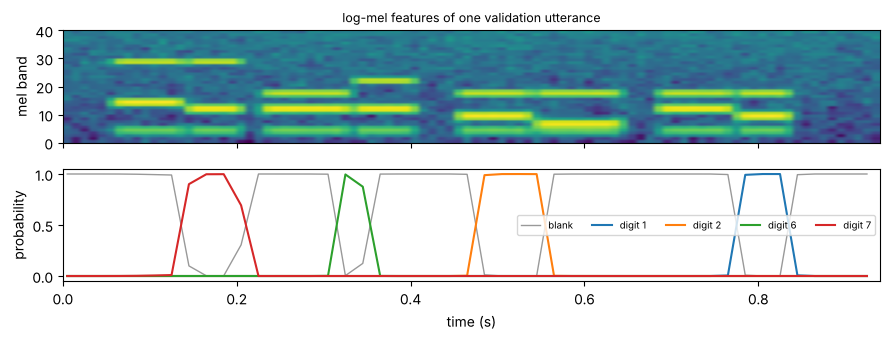

references containing ছয় or নয়: 188 of 300 (256 copies of য়)
CER without normalization: 0.1032; after NFC on both sides: 0.0000


In [6]:
k = 3
x, lengths, _, _ = batch(Xva, Yva, [k])
model.eval()
with torch.no_grad():
    lp, out_len = model(x, lengths)
model.train()
probs = lp[0].exp().numpy()
print("reference: ", to_text(Yva[k]), " digits", [int(d) for d in Yva[k]])
print("recognized:", to_text(greedy_decode(lp, out_len)[0]))
print(f"frames where the blank has probability above 0.5: {(probs[:, 0] > 0.5).mean():.2f}")

fig, ax = plt.subplots(2, 1, figsize=(9, 3.5), sharex=True)
ax[0].imshow(Xva[k].T, origin="lower", aspect="auto", extent=[0, len(Xva[k]) * HOP / SR, 0, NMEL])
ax[0].set_ylabel("mel band"); ax[0].set_title("log-mel features of one validation utterance", fontsize=9)
tt = (np.arange(len(probs)) * 2 + 0.5) * HOP / SR
ax[1].plot(tt, probs[:, 0], color="0.6", lw=1, label="blank")
for d in range(10):
    if probs[:, d + 1].max() > 0.3:
        ax[1].plot(tt, probs[:, d + 1], lw=1.5, label=f"digit {d}")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("probability"); ax[1].legend(fontsize=7, ncol=6, loc="center right")
plt.tight_layout(); plt.show()

hyps = [to_text(h) for h in recognize(model, Xva)]
refs = [to_text(y) for y in Yva]
refs_typed = [r.replace("য়", "য়") for r in refs]              # the same words typed with one-code-point য়
nfc = lambda s: unicodedata.normalize("NFC", s)
n_ya = sum(r.count("য়") for r in refs_typed)
print(f"references containing ছয় or নয়: {sum(r != t for r, t in zip(refs, refs_typed))} of {len(refs)} ({n_ya} copies of য়)")
print(f"CER without normalization: {cer(refs_typed, hyps):.4f}; after NFC on both sides: {cer([nfc(r) for r in refs_typed], [nfc(h) for h in hyps]):.4f}")

### 7. Clean speech is not a market
The recognizer was trained with white noise between 10 and 30 dB SNR. We now test it on 200 new utterances per condition: white noise from 30 dB down to −5 dB, and a "market" condition where three other synthetic speakers talk at the same time (babble) at the given SNR, on top of white noise at 20 dB.

SNR (dB)                                 30          20          10           5           0          -5
white noise                      0.000/0.000  0.000/0.000  0.004/0.005  0.059/0.072  0.379/0.411  0.836/0.856   (WER/CER)
babble + white noise at 20 dB    0.001/0.001  0.011/0.011  0.329/0.303  0.668/0.598  1.019/0.891  1.153/0.984   (WER/CER)


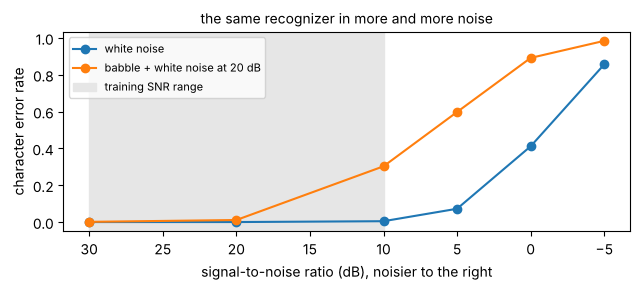

runtime so far 27 s


In [7]:
test_rng = np.random.default_rng(2)
snrs = [30, 20, 10, 5, 0, -5]
results = {"white noise": [], "babble + white noise at 20 dB": []}
for s in snrs:
    Xt, Yt = make_set(200, test_rng, snr=s)
    results["white noise"].append(score(model, Xt, Yt))
    Xt, Yt = make_set(200, test_rng, snr=20, babble_snr=s)
    results["babble + white noise at 20 dB"].append(score(model, Xt, Yt))
print("SNR (dB)                       " + "".join(f"{s:>12d}" for s in snrs))
for name, r in results.items():
    print(f"{name:31s}" + "".join(f"  {w:.3f}/{c:.3f}" for w, c in r) + "   (WER/CER)")

plt.figure(figsize=(6.5, 3))
for name, r in results.items():
    plt.plot(snrs, [c for _, c in r], "o-", label=name)
plt.axvspan(10, 30, color="0.9", label="training SNR range")
plt.gca().invert_xaxis(); plt.xlabel("signal-to-noise ratio (dB), noisier to the right"); plt.ylabel("character error rate")
plt.title("the same recognizer in more and more noise", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 8. A real recognizer on real Bangla speech (NOT RUN here)
Whisper (Radford et al. 2022) is an encoder–decoder model trained on 680,000 hours of labelled audio from the web, including Bangla. Mozilla Common Voice (Ardila et al. 2020) has read Bangla speech recorded by volunteers; download a clip and its transcript from the Common Voice website after accepting its terms. A wav2vec 2.0 or XLS-R model fine-tuned for Bangla with CTC can be scored the same way through the `transformers` library. Remove punctuation and apply NFC to both sides before scoring.

In [ ]:
# NOT RUN: needs the openai-whisper package (pip install openai-whisper), ffmpeg, a model download and a Common Voice clip
import whisper
asr = whisper.load_model("small")                                  # 244 M parameters; larger models are slower but more accurate
clip = "common_voice_bn_clip.mp3"                                  # one clip from the Common Voice Bangla test set
reference = "..."                                                  # its transcript, copied from the dataset's test file
result = asr.transcribe(clip, language="bn")
clean = lambda s: unicodedata.normalize("NFC", "".join(ch for ch in s if ch not in "।,.?!;:-\"'")).strip()
print("hypothesis:", result["text"])
print(f"WER {wer([clean(reference)], [clean(result['text'])]):.3f}, CER {cer([clean(reference)], [clean(result['text'])]):.3f}")

### 9. Exercises

In [8]:
# TODO: noise augmentation. Build a training set in which half of the utterances also contain babble at a random SNR
# between 0 and 20 dB (use make_set with babble_snr), train a new CTCRecognizer on it for 6 epochs, and fill the
# "market" row of section 7 again. Does training on babble help, and what does it cost on white noise?
def train_with_babble():
    return None          # replace with your code: return the new model

m2 = train_with_babble()
print("not done yet" if m2 is None else "trained; now re-run the section 7 loop with model = m2")

not done yet


In [9]:
# TODO: an error breakdown. Extend edit_distance with a backtrace so that it returns the numbers of substitutions,
# deletions and insertions separately, and report them for the white-noise test set at 0 dB.
def error_counts(ref_words, hyp_words):
    return None          # replace with your code: return (substitutions, deletions, insertions)

r = error_counts("এক দুই তিন".split(), "এক তিন তিন চার".split())
print("not done yet" if r is None else f"S, D, I = {r} (expected one substitution and one insertion, or another split with 2 edits)")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **The hand calculations check out.** A 25 ms window at 8 kHz is 200 samples, the 10 ms hop is 80 samples, and 98 complete windows fit in one second. The mel scale puts 1,000 Hz at 1000.0 mel but 4,000 Hz at only 2146.1, so high frequencies are squeezed together. `a a - a b b - b` collapses to `aabb`: the blank between the two a's is what lets CTC write a double letter. Five 3-frame sequences give `ab`, and PyTorch's CTC loss with uniform probabilities was 1.6864 = −log(5/27).
2. **Features shrink the input.** Our NumPy STFT matched SciPy's to 7.1e-15. One second of audio (8,000 samples) became 98 × 40 = 3,920 log-mel numbers. The first mel filter spans 0–68 Hz and the last 3,583–4,000 Hz.
3. **CTC training has a slow start.** After the first epoch the validation WER was 1.000: the model output only blanks, which is common early in CTC training. It fell to 0.047 after epoch 2 and 0.000 after epoch 6, with 64,203 parameters and a few seconds per epoch on one CPU thread (timings vary with the load on the machine). This synthetic task is far easier than real speech, so do not read these numbers as what a Bangla recognizer achieves.
4. **CTC outputs are mostly blank.** In the plotted utterance the blank had probability above 0.5 in 72% of the output frames, and each digit appeared as a burst a few frames long.
5. **Normalize before you score.** 188 of the 300 validation references contain ছয় or নয়. When the references used the one-code-point য় and the recognizer wrote the two-code-point form, a perfect transcript scored CER 0.1032; after NFC on both sides it scored 0.0000.
6. **Noise that sounds like speech is the worst.** With white noise the WER stayed at 0.000 at 30 and 20 dB and 0.004 at 10 dB, the edge of the training range, then rose to 0.059 at 5 dB, 0.379 at 0 dB and 0.836 at −5 dB. With three other speakers in the background (plus white noise at 20 dB) the WER was already 0.329 at 10 dB, against 0.004 for white noise at the same SNR, and passed 1 at 0 dB (1.019) and −5 dB (1.153): the model wrote down the other speakers' digits as extra words. A recognizer tested only on clean, single-speaker speech tells you little about a market.